<a href="https://colab.research.google.com/github/Roun-02/DSMBC-Online-Shoppers-Intention/blob/main/DSMBC_Online_Shoppers_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PREPROCESSING**
## Tahap lanjutan dari EDA: Online Shoppers Purchasing Intention

Notebook ini melanjutkan EDA (`DSMBC_Online_Shoppers_Intention_EDA.ipynb`). Tujuannya mengubah data mentah menjadi data yang siap dipakai model **tanpa kebocoran informasi (*data leakage*)**, dengan setiap keputusan berpijak pada temuan EDA.

## Dari catatan EDA ke tindakan preprocessing

| Catatan dari EDA | Tindakan di notebook ini | Bagian |
|---|---|---|
| 125 baris duplikat, semuanya `Revenue = False` | Dibuang **sebelum** split agar baris identik tidak masuk ke train dan test sekaligus | 2.2 |
| Anomali kecil (`BounceRates > ExitRates`, sesi tanpa halaman) | Dicek dampaknya, lalu dipertahankan | 2.3 |
| Fitur miring ke kanan dan outlier yang nyata | Outlier tidak dibuang; `log1p` + scaling untuk model linear, fitur mentah untuk model pohon | 3, 8.2, 8.3 |
| Kelas tidak seimbang (15,5% pembeli) | **Stratified split** dan bobot kelas; tidak ada resampling pada data uji | 4, 8.6, 9 |
| `BounceRates`–`ExitRates` (r = 0,91) dan pasangan jumlah–durasi | Cek VIF; `BounceRates` dilepas **hanya** untuk jalur model linear | 5, 8.4 |
| Kode `OperatingSystems`, `Browser`, `Region`, `TrafficType` adalah label | One-hot encoding; kode jarang digabung menjadi satu kelompok | 6, 7, 8.5 |
| `PageValues` berpotensi *leakage* | Disiapkan dua versi fitur: **dengan** dan **tanpa** `PageValues` | 7, 8 |

**Prinsip yang dijaga:** semua yang "dipelajari" dari data (rata-rata untuk scaling, daftar kategori, kategori jarang) hanya dihitung dari **data latih**, lalu diterapkan ke data uji.

Setiap keputusan di atas juga dibandingkan dengan metode alternatif (beserta angkanya) pada bagian **8.2–8.8**.

# **1. INISIALISASI**

In [1]:
import os, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (8, 5)

RANDOM_STATE = 42

In [2]:
# Pakai file lokal bila ada, jika tidak ambil dari URL yang sama dengan EDA
url = "https://raw.githubusercontent.com/Roun-02/DSMBC-Online-Shoppers-Intention/refs/heads/main/online_shoppers_intention.csv"
local_candidates = ["online_shoppers_intention.csv", "data/online_shoppers_intention.csv",
                    "/mnt/user-data/uploads/online_shoppers_intention.csv"]
path = next((p for p in local_candidates if os.path.exists(p)), url)
df = pd.read_csv(path)

# Pengelompokan kolom (sama dengan EDA)
num_cols = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',
            'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates',
            'PageValues', 'SpecialDay']
cat_cols = ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']
target = 'Revenue'
assert sorted(num_cols + cat_cols + [target]) == sorted(df.columns)

print("Sumber data:", path)
print("Ukuran data:", df.shape)

Sumber data: https://raw.githubusercontent.com/Roun-02/DSMBC-Online-Shoppers-Intention/refs/heads/main/online_shoppers_intention.csv
Ukuran data: (12330, 18)


# **2. PEMBERSIHAN DATA**

## 2.1 Tipe data

In [3]:
# Revenue dan Weekend bertipe boolean -> ubah ke 0/1 agar bisa dipakai model dan dihitung rata-ratanya
df[target] = df[target].astype(int)
df['Weekend'] = df['Weekend'].astype(int)

print("Missing value total:", df.isna().sum().sum())
df.dtypes.value_counts()

Missing value total: 0


int64      9
float64    7
str        2
Name: count, dtype: int64

**Interpretasi:** tidak ada missing value. `Revenue` dan `Weekend` kini berupa 0/1, sehingga tersisa 9 kolom integer, 7 kolom desimal, dan 2 kolom teks (`Month`, `VisitorType`) yang akan di-encode.

## 2.2 Duplikat

In [4]:
dup_mask = df.duplicated(keep='first')
df_clean = df.drop_duplicates().reset_index(drop=True)

hasil = pd.DataFrame({
    'jumlah_sesi': [len(df), len(df_clean)],
    'pembeli': [df[target].sum(), df_clean[target].sum()],
    'conv_rate_%': [df[target].mean()*100, df_clean[target].mean()*100],
}, index=['sebelum', 'sesudah dibuang duplikat'])
display(hasil)
print("Duplikat yang dibuang:", dup_mask.sum(), "| Revenue=True di antara duplikat:", df.loc[dup_mask, target].sum())

,jumlah_sesi,pembeli,conv_rate_%
sebelum,12330,1908,15.474453
sesudah dibuang duplikat,12205,1908,15.632937


Duplikat yang dibuang: 125 | Revenue=True di antara duplikat: 0


**Interpretasi:** 125 duplikat dibuang dan seluruhnya `Revenue = False`, sehingga jumlah pembeli tetap 1.908 dan conversion rate hanya naik dari 15,47% ke 15,63%. Tersisa 12.205 sesi. Pembuangan dilakukan sebelum split agar baris identik tidak berada di data latih dan data uji sekaligus (yang akan membuat skor uji terlalu optimistis).

## 2.3 Anomali kecil dari EDA

In [5]:
page_total = df_clean['Administrative'] + df_clean['Informational'] + df_clean['ProductRelated']
m_be = df_clean['BounceRates'] > df_clean['ExitRates']
m_nopage = page_total == 0

anom = pd.DataFrame({
    'jumlah_sesi': [m_be.sum(), m_nopage.sum()],
    'persen_data': [m_be.mean()*100, m_nopage.mean()*100],
    'conv_rate_%': [df_clean.loc[m_be, target].mean()*100, df_clean.loc[m_nopage, target].mean()*100],
}, index=['BounceRates > ExitRates', 'Tanpa halaman sama sekali'])
display(anom)
print(f"Conv rate seluruh data: {df_clean[target].mean()*100:.2f}%")

,jumlah_sesi,persen_data,conv_rate_%
BounceRates > ExitRates,175,1.433839,10.857143
Tanpa halaman sama sekali,6,0.049160,0.000000


Conv rate seluruh data: 15.63%


**Interpretasi:** 175 sesi (1,4%) memiliki `BounceRates > ExitRates` dengan conversion rate 10,9%, sedikit di bawah rata-rata 15,6%, tetapi tidak ekstrem. Enam sesi tanpa halaman semuanya tidak membeli. Keduanya **dipertahankan**: jumlahnya kecil, dan tidak ada bukti bahwa label `Revenue`-nya salah.

# **3. OUTLIER DAN KEMIRINGAN (SKEWNESS)**

In [6]:
skew_cols = [c for c in num_cols if c != 'SpecialDay']     # SpecialDay hanya 0-1, tidak perlu log

# Apakah nilai ekstrem (di atas persentil 99) adalah sesi "aneh"? Lihat conversion rate-nya
rows = []
for c in skew_cols:
    thr = df_clean[c].quantile(.99)
    top = df_clean[c] > thr
    rows.append({'fitur': c, 'batas_P99': thr, 'jumlah_sesi_ekstrem': top.sum(),
                 'conv_rate_sesi_ekstrem_%': df_clean.loc[top, target].mean()*100})
display(pd.DataFrame(rows).set_index('fitur'))

,batas_P99,jumlah_sesi_ekstrem,conv_rate_sesi_ekstrem_%
fitur,,,
Administrative,14.000000,113,23.893805
Administrative_Duration,838.704889,123,21.138211
Informational,6.000000,83,24.096386
Informational_Duration,722.379200,123,26.016260
ProductRelated,221.000000,122,36.885246
ProductRelated_Duration,8704.271573,123,34.146341
BounceRates,0.200000,0,NaN
ExitRates,0.200000,0,NaN
PageValues,86.108689,123,86.991870


**Interpretasi:** sesi di atas persentil 99 bukan sesi "aneh". Conversion rate-nya 21–37% pada fitur halaman dan durasi, dan **87% pada `PageValues`**, jauh di atas rata-rata 15,6%. Membuang outlier berarti membuang pembeli yang paling jelas, sehingga **outlier tidak dibuang**. `BounceRates` dan `ExitRates` tidak punya nilai di atas P99 karena P99 sama dengan nilai maksimumnya (0,2).

,skew_asli,skew_setelah_log1p,persen_nol
Administrative,1.95,0.55,46.24
Administrative_Duration,5.59,0.24,47.34
Informational,4.01,2.01,78.44
Informational_Duration,7.54,1.90,80.29
ProductRelated,4.33,-0.04,0.31
ProductRelated_Duration,7.25,-1.43,5.16
BounceRates,3.16,3.08,45.21
ExitRates,2.23,2.13,0.62
PageValues,6.35,1.79,77.63


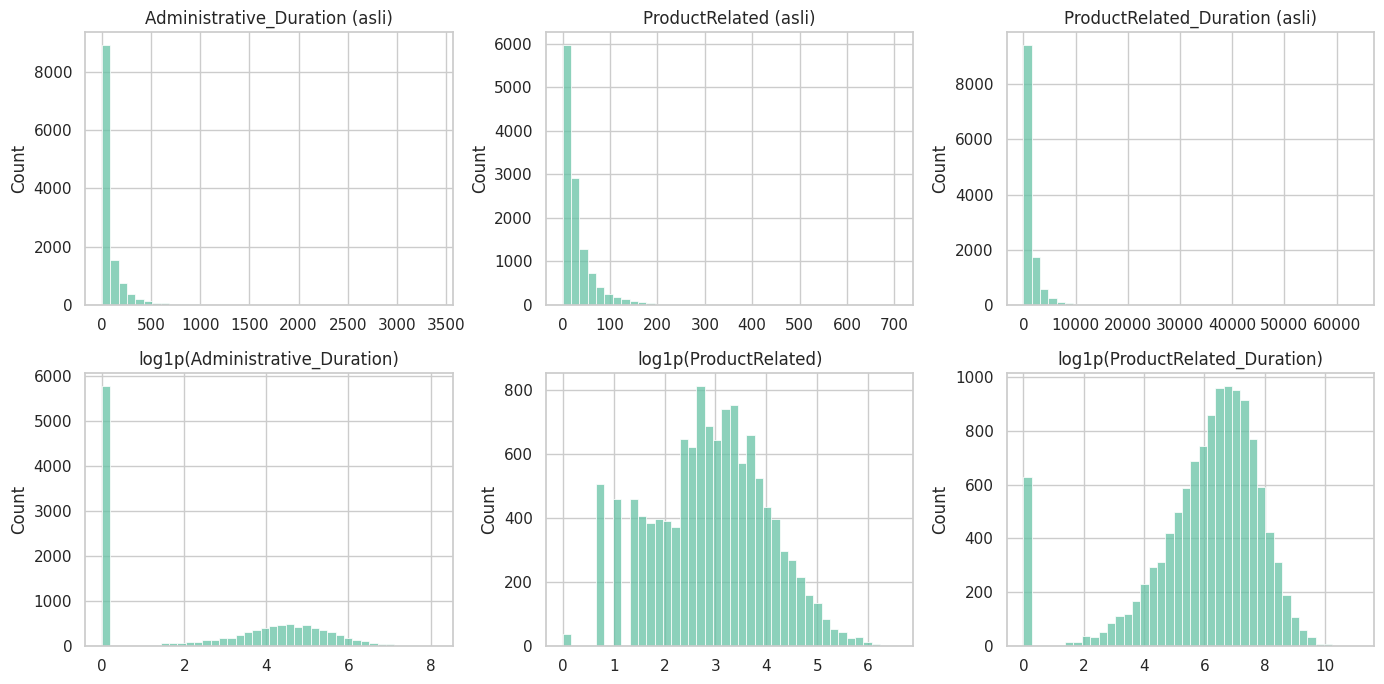

In [7]:
skew_tbl = pd.DataFrame({
    'skew_asli': df_clean[skew_cols].skew(),
    'skew_setelah_log1p': np.log1p(df_clean[skew_cols]).skew(),
    'persen_nol': (df_clean[skew_cols] == 0).mean() * 100,
})
display(skew_tbl.round(2))

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for j, c in enumerate(['Administrative_Duration', 'ProductRelated', 'ProductRelated_Duration']):
    sns.histplot(df_clean[c], bins=40, ax=axes[0, j]); axes[0, j].set_title(f"{c} (asli)")
    sns.histplot(np.log1p(df_clean[c]), bins=40, ax=axes[1, j]); axes[1, j].set_title(f"log1p({c})")
    axes[0, j].set_xlabel(""); axes[1, j].set_xlabel("")
plt.tight_layout(); plt.show()

**Interpretasi:** `log1p` menurunkan kemiringan secara nyata pada `Administrative_Duration` (5,59 → 0,24), `ProductRelated` (4,33 → −0,04), dan `PageValues` (6,35 → 1,79). Ada tiga catatan: (1) `Informational` dan durasinya masih miring (±2,0) karena 78–80% nilainya nol, dan tumpukan nol tidak hilang oleh log; (2) `BounceRates` dan `ExitRates` nyaris tidak berubah karena rentangnya hanya 0–0,2; (3) `ProductRelated_Duration` menjadi sedikit miring ke kiri (−1,43). Ini cukup baik untuk model linear; model pohon tidak memerlukan transformasi.

# **4. PEMBAGIAN DATA LATIH DAN DATA UJI**

Split dilakukan **sebelum** langkah yang "belajar" dari data (scaling, encoding, penggabungan kategori jarang). Dengan stratifikasi, proporsi pembeli di train dan test dijaga sama.

In [8]:
X = df_clean.drop(columns=target)
y = df_clean[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

split_tbl = pd.DataFrame({
    'jumlah_sesi': [len(y_train), len(y_test)],
    'pembeli': [y_train.sum(), y_test.sum()],
    'conv_rate_%': [y_train.mean()*100, y_test.mean()*100],
}, index=['train', 'test'])
display(split_tbl)

# Cek sebaran bulan dan tipe pengunjung di kedua bagian
sel = pd.concat({'train': X_train['VisitorType'].value_counts(normalize=True),
                 'test': X_test['VisitorType'].value_counts(normalize=True)}, axis=1) * 100
display(sel.round(2))
sel_m = pd.concat({'train': X_train['Month'].value_counts(normalize=True),
                   'test': X_test['Month'].value_counts(normalize=True)}, axis=1) * 100
print(f"Selisih terbesar proporsi bulan train vs test: {(sel_m['train']-sel_m['test']).abs().max():.2f} poin persentase")

,jumlah_sesi,pembeli,conv_rate_%
train,9764,1526,15.628841
test,2441,382,15.649324


,train,test
VisitorType,,
Returning_Visitor,85.49,85.37
New_Visitor,13.82,14.09
Other,0.70,0.53


Selisih terbesar proporsi bulan train vs test: 1.41 poin persentase


**Interpretasi:** data terbagi menjadi 9.764 sesi latih dan 2.441 sesi uji dengan proporsi pembeli hampir identik (15,63% vs 15,65%). Proporsi tipe pengunjung selisih kurang dari 0,3 poin dan proporsi bulan selisih maksimum 1,41 poin, jadi data uji representatif terhadap data latih.

# **5. MULTIKOLINEARITAS**

Diukur dengan **VIF** (*Variance Inflation Factor*): VIF di atas ±5 berarti fitur tersebut sebagian besar bisa "ditebak" dari fitur lain. Dihitung pada data latih setelah `log1p` dan standardisasi.

In [9]:
Z = np.log1p(X_train[skew_cols])
Z = (Z - Z.mean()) / Z.std()

def vif_series(M):
    # VIF = elemen diagonal dari invers matriks korelasi
    R = np.corrcoef(M.values, rowvar=False)
    return pd.Series(np.diag(np.linalg.inv(R)), index=M.columns)

vif_tbl = pd.DataFrame({
    'VIF_semua_fitur': vif_series(Z),
    'VIF_tanpa_BounceRates': vif_series(Z.drop(columns='BounceRates')),
})
display(vif_tbl.round(2))

pairs = [('BounceRates', 'ExitRates'), ('ProductRelated', 'ProductRelated_Duration'),
         ('Administrative', 'Administrative_Duration'), ('Informational', 'Informational_Duration')]
print("Korelasi setelah log1p (data latih):")
for a, b in pairs:
    print(f"  {a:15s} vs {b:25s}: {Z[a].corr(Z[b]):.2f}")

,VIF_semua_fitur,VIF_tanpa_BounceRates
Administrative,7.40,7.37
Administrative_Duration,7.19,7.11
BounceRates,6.05,NaN
ExitRates,7.16,2.50
Informational,6.37,6.36
Informational_Duration,6.29,6.28
PageValues,1.13,1.12
ProductRelated,4.83,4.16
ProductRelated_Duration,6.24,5.60


Korelasi setelah log1p (data latih):
  BounceRates     vs ExitRates                : 0.89
  ProductRelated  vs ProductRelated_Duration  : 0.85
  Administrative  vs Administrative_Duration  : 0.92
  Informational   vs Informational_Duration   : 0.92


**Interpretasi:** setelah `log1p`, pasangan jumlah halaman dan durasinya berkorelasi 0,85–0,92 sehingga VIF-nya 6–7 (di atas batas ±5). `BounceRates` dan `ExitRates` berkorelasi 0,89. Melepas `BounceRates` menurunkan VIF `ExitRates` dari 7,16 ke 2,50. `ExitRates` yang dipertahankan karena kaitannya dengan `Revenue` lebih kuat di EDA (−0,21 vs −0,15). Pasangan jumlah–durasi **tidak dilepas**: keduanya membawa informasi berbeda (berapa banyak vs berapa lama) dan dampaknya bisa diredam dengan regularisasi pada Logistic Regression. `PageValues` hampir bebas kolinearitas (VIF 1,1).

# **6. KATEGORI JARANG PADA KODE NOMINAL**

In [10]:
nominal_cols = ['OperatingSystems', 'Browser', 'Region', 'TrafficType']   # kode = label, bukan urutan
MIN_FREQ = 100                                                           # kode dengan < 100 sesi di train digabung

rows = []
for c in nominal_cols:
    vc = X_train[c].value_counts()
    rare = vc[vc < MIN_FREQ]
    rows.append({'kolom': c, 'jumlah_kode': len(vc), 'kode_jarang': len(rare),
                 'kode_dipertahankan': len(vc) - len(rare),
                 'sesi_di_kode_jarang': rare.sum(), 'persen_sesi': rare.sum() / len(X_train) * 100,
                 'daftar_kode_jarang': sorted(rare.index.tolist())})
display(pd.DataFrame(rows).set_index('kolom').round(2))
print("VisitorType (train):", X_train['VisitorType'].value_counts().to_dict())

,jumlah_kode,kode_jarang,kode_dipertahankan,sesi_di_kode_jarang,persen_sesi,daftar_kode_jarang
kolom,,,,,,
OperatingSystems,8,4,4,86,0.88,"[5, 6, 7, 8]"
Browser,13,6,7,186,1.90,"[3, 7, 9, 11, 12, 13]"
Region,9,0,9,0,0.00,[]
TrafficType,19,8,11,136,1.39,"[7, 9, 14, 15, 16, 17, 18, 19]"


VisitorType (train): {'Returning_Visitor': 8347, 'New_Visitor': 1349, 'Other': 68}


**Interpretasi:** `Region` tidak punya kode jarang. Kode jarang hanya berasal dari `OperatingSystems` (4 kode, 86 sesi), `Browser` (6 kode, 186 sesi), dan `TrafficType` (8 kode, 136 sesi), yaitu 0,9–1,9% sesi per kolom. Penggabungan ini mengurangi jumlah kolom tanpa membuang banyak informasi. `VisitorType = Other` (68 sesi) tetap dipertahankan sebagai kategori sendiri karena maknanya jelas.

# **7. MEMBANGUN PIPELINE PREPROCESSING**

Dua jalur disiapkan karena kebutuhan modelnya berbeda:

| Jalur | Dipakai untuk | Perlakuan numerik | Kategorikal |
|---|---|---|---|
| `linear` | Logistic Regression | `log1p` + standardisasi; `BounceRates` dilepas | One-hot (kode jarang digabung) |
| `tree` | Decision Tree, Random Forest, Gradient Boosting | Dibiarkan apa adanya (pohon tidak terpengaruh skala atau skew) | One-hot (kode jarang digabung) |

In [11]:
log_tf = FunctionTransformer(np.log1p, feature_names_out='one-to-one')

def make_preprocessor(branch='linear', use_log=True, drop_bounce=True, drop_pagevalues=False):
    # branch: 'linear' atau 'tree'. Argumen lain dipakai untuk uji perbandingan di bagian ablation.
    num = list(num_cols)
    if drop_pagevalues:
        num.remove('PageValues')
    if branch == 'linear':
        if drop_bounce:
            num.remove('BounceRates')
        skew = [c for c in num if c != 'SpecialDay']
        scaler = Pipeline([('log', log_tf), ('scale', StandardScaler())]) if use_log else StandardScaler()
        numeric = [('num_skew', scaler, skew), ('num_lain', StandardScaler(), ['SpecialDay'])]
    else:
        numeric = [('num', 'passthrough', num)]
    categorical = [
        ('nominal', OneHotEncoder(min_frequency=MIN_FREQ, handle_unknown='infrequent_if_exist', sparse_output=False), nominal_cols),
        ('kategori', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['Month', 'VisitorType']),
        ('biner', 'passthrough', ['Weekend']),
    ]
    return ColumnTransformer(numeric + categorical, verbose_feature_names_out=False).set_output(transform='pandas')

# Fit HANYA pada data latih, lalu terapkan ke data uji
prep_linear = make_preprocessor('linear').fit(X_train)
prep_tree = make_preprocessor('tree').fit(X_train)

Xtr_lin, Xte_lin = prep_linear.transform(X_train), prep_linear.transform(X_test)
Xtr_tree, Xte_tree = prep_tree.transform(X_train), prep_tree.transform(X_test)

print("Jalur linear :", Xtr_lin.shape, Xte_lin.shape)
print("Jalur tree   :", Xtr_tree.shape, Xte_tree.shape)
print("\nKode yang digabung menjadi 'infrequent' (dipelajari dari data latih):")
for c, cats in zip(nominal_cols, prep_linear.named_transformers_['nominal'].infrequent_categories_):
    print(f"  {c:17s}: {None if cats is None else [int(k) for k in cats]}")

Jalur linear : (9764, 57) (2441, 57)
Jalur tree   : (9764, 58) (2441, 58)

Kode yang digabung menjadi 'infrequent' (dipelajari dari data latih):
  OperatingSystems : [5, 6, 7, 8]
  Browser          : [3, 7, 9, 11, 12, 13]
  Region           : None
  TrafficType      : [7, 9, 14, 15, 16, 17, 18, 19]


**Interpretasi:** jalur linear menghasilkan 57 kolom dan jalur pohon 58 kolom (selisih satu kolom adalah `BounceRates`). Kode yang digabung dipelajari **hanya dari data latih** (misalnya OS 5–8, dan `TrafficType` 7, 9, 14–19). Kode yang belum pernah terlihat di data uji akan dimasukkan ke kelompok jarang bila kelompok itu ada.

In [12]:
# Uji kewajaran (sanity check)
assert not Xtr_lin.isna().any().any() and not Xte_lin.isna().any().any()
assert not Xtr_tree.isna().any().any() and not Xte_tree.isna().any().any()
assert list(Xtr_lin.columns) == list(Xte_lin.columns)

scaled = [c for c in Xtr_lin.columns if c in num_cols]
cek = pd.DataFrame({
    'mean_train': Xtr_lin[scaled].mean(), 'std_train': Xtr_lin[scaled].std(),
    'mean_test': Xte_lin[scaled].mean(), 'std_test': Xte_lin[scaled].std(),
})
display(cek.round(3))
print("Kolom hasil (jalur linear):")
print(list(Xtr_lin.columns))

,mean_train,std_train,mean_test,std_test
Administrative,0.0,1.0,-0.000,0.997
Administrative_Duration,-0.0,1.0,-0.002,0.995
Informational,0.0,1.0,-0.005,0.994
Informational_Duration,0.0,1.0,0.012,1.012
ProductRelated,-0.0,1.0,0.004,0.985
ProductRelated_Duration,-0.0,1.0,-0.010,1.003
ExitRates,0.0,1.0,-0.000,1.002
PageValues,-0.0,1.0,0.006,1.011
SpecialDay,0.0,1.0,-0.010,0.993


Kolom hasil (jalur linear):
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems_1', 'OperatingSystems_2', 'OperatingSystems_3', 'OperatingSystems_4', 'OperatingSystems_infrequent_sklearn', 'Browser_1', 'Browser_2', 'Browser_4', 'Browser_5', 'Browser_6', 'Browser_8', 'Browser_10', 'Browser_infrequent_sklearn', 'Region_1', 'Region_2', 'Region_3', 'Region_4', 'Region_5', 'Region_6', 'Region_7', 'Region_8', 'Region_9', 'TrafficType_1', 'TrafficType_2', 'TrafficType_3', 'TrafficType_4', 'TrafficType_5', 'TrafficType_6', 'TrafficType_8', 'TrafficType_10', 'TrafficType_11', 'TrafficType_13', 'TrafficType_20', 'TrafficType_infrequent_sklearn', 'Month_Aug', 'Month_Dec', 'Month_Feb', 'Month_Jul', 'Month_June', 'Month_Mar', 'Month_May', 'Month_Nov', 'Month_Oct', 'Month_Sep', 'VisitorType_New_Visitor', 'VisitorType_Other', 'VisitorType_Returning_Visitor', 'We

**Interpretasi:** tidak ada nilai kosong dan kolom data latih dan data uji identik. Pada data latih rata-rata tepat 0 dan standar deviasi tepat 1, sedangkan pada data uji hanya mendekati (rata-rata −0,01 sampai 0,01, std 0,99–1,01). Perbedaan kecil ini justru bukti bahwa scaler dipelajari dari data latih saja dan tidak "mengintip" data uji.

# **8. PENGUJIAN KEPUTUSAN PREPROCESSING (CROSS-VALIDATION PADA DATA LATIH)**

Untuk memastikan pilihan di atas tidak sekadar asumsi, empat konfigurasi dibandingkan dengan Logistic Regression sederhana memakai *stratified 5-fold CV* **pada data latih saja** (data uji tidak disentuh). Pipeline dipasang ulang di setiap fold sehingga tidak ada kebocoran. Metrik: **PR-AUC** (*average precision*).

> Ini bukan hasil model final. Tujuannya hanya menguji keputusan preprocessing.

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_pr_auc(prep):
    pipe = Pipeline([('prep', prep),
                     ('clf', LogisticRegression(class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE))])
    s = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='average_precision')
    return s.mean(), s.std()

konfigurasi = {
    '1. Tanpa log, semua fitur':                    make_preprocessor('linear', use_log=False, drop_bounce=False),
    '2. + log1p':                                   make_preprocessor('linear', use_log=True,  drop_bounce=False),
    '3. + log1p, tanpa BounceRates (pilihan)':      make_preprocessor('linear', use_log=True,  drop_bounce=True),
    '4. Pilihan, tanpa PageValues (skenario leakage)': make_preprocessor('linear', use_log=True, drop_bounce=True, drop_pagevalues=True),
}
rows = []
for nama, prep in konfigurasi.items():
    m, s = cv_pr_auc(prep)
    rows.append({'konfigurasi': nama, 'PR-AUC_rata2': m, 'std': s})
ablation = pd.DataFrame(rows).set_index('konfigurasi')
display(ablation.round(3))
print(f"Pembanding: PR-AUC model asal tebak = proporsi pembeli = {y_train.mean():.3f}")

,PR-AUC_rata2,std
konfigurasi,,
"1. Tanpa log, semua fitur",0.647,0.023
2. + log1p,0.663,0.023
"3. + log1p, tanpa BounceRates (pilihan)",0.664,0.022
"4. Pilihan, tanpa PageValues (skenario leakage)",0.332,0.032


Pembanding: PR-AUC model asal tebak = proporsi pembeli = 0.156


**Interpretasi:** `log1p` menaikkan PR-AUC dari 0,647 ke 0,663, dan melepas `BounceRates` hampir tidak mengubahnya (0,664), jadi kedua keputusan **tidak merugikan**. Selisih `log1p` (0,016) lebih kecil dari variasi antar fold (±0,02), sehingga dibaca sebagai "tidak merugikan dan kemungkinan sedikit membantu", bukan perbaikan pasti. Temuan terbesar: **tanpa `PageValues` PR-AUC turun separuh (0,664 → 0,332)**, walaupun masih sekitar 2 kali di atas tebakan acak (0,156). Artinya kemampuan prediksi model linear sangat bergantung pada satu fitur yang berisiko *leakage*. Jika `PageValues` tidak tersedia saat keputusan real-time, performa realistisnya jauh lebih rendah, jadi dua versi fitur dipertahankan.

**Pembaruan:** bagian 8.2–8.7 mengulang perbandingan ini dengan CV 5×3 berpasangan dan metode alternatif. `log1p` mengalahkan tanpa transformasi di 14 dari 15 fold, jadi selisih 0,016 itu konsisten, bukan sekadar derau.

## 8.1 Perbandingan metode alternatif: cara menilai

Bagian 8 di atas hanya membandingkan satu pilihan dengan beberapa varian dekatnya, dengan 5-fold CV sekali jalan. Sub-bagian 8.1–8.7 ini membandingkan setiap keputusan preprocessing dengan **metode alternatif yang umum dipakai**, supaya alasan memilihnya berbasis angka.

**Cara menilai (sama untuk semua perbandingan):**
- Data: hanya **data latih**. Data uji tidak disentuh.
- Validasi: *stratified* 5-fold **diulang 3 kali** (15 skor per metode). Semua metode memakai pembagian fold yang persis sama, sehingga selisih bisa dibandingkan berpasangan.
- Model penguji: Logistic Regression (jalur linear) dan Gradient Boosting (jalur pohon). Metrik utama PR-AUC.
- Setiap transformer dipasang ulang di dalam tiap fold, jadi tidak ada kebocoran.
- Kolom **selisih_vs_pilihan** = skor metode itu dikurangi skor pilihan; **menang_dari_15** = berapa fold metode itu mengalahkan pilihan.
- Kolom **putusan**: *setara* bila |rata-rata selisih| tidak lebih besar dari simpangan baku selisih antar fold. Aturan ini sengaja konservatif: selisih kecil tidak dibaca sebagai kemenangan.

**Keterbatasan:** fold hasil pengulangan tidak sepenuhnya independen, sehingga simpangan baku selisih cenderung terlalu kecil. Putusan *setara* lebih bisa dipercaya daripada *lebih baik / lebih buruk*. Hasil juga hanya berlaku untuk dua model penguji di atas.

In [14]:
# Alat bantu perbandingan: semua metode dinilai dengan CV yang SAMA (5-fold x 3 ulangan = 15 skor per metode)
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.preprocessing import MinMaxScaler, RobustScaler, PowerTransformer, QuantileTransformer, OrdinalEncoder
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.base import BaseEstimator, TransformerMixin

cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
from sklearn.metrics import make_scorer, precision_recall_curve

def f1_ambang_terbaik(y_true, proba):
    # F1 tertinggi yang bisa dicapai bila ambang dipilih optimal pada fold itu (adil untuk membandingkan model berbobot vs tidak)
    p, r, _ = precision_recall_curve(y_true, proba)
    return np.max(2 * p * r / np.clip(p + r, 1e-12, None))

SCORING = {'pr_auc': 'average_precision', 'roc_auc': 'roc_auc', 'f1': 'f1', 'recall': 'recall', 'precision': 'precision',
           'f1_maks': make_scorer(f1_ambang_terbaik, response_method='predict_proba')}

class ClipP99(BaseEstimator, TransformerMixin):
    """Winsorizing: nilai di atas persentil ke-q dipotong. Batas dipelajari dari data latih (per fold)."""
    def __init__(self, q=0.99):
        self.q = q
    def fit(self, X, y=None):
        self.hi_ = np.quantile(np.asarray(X), self.q, axis=0)
        return self
    def transform(self, X):
        return np.minimum(np.asarray(X), self.hi_)
    def get_feature_names_out(self, names=None):
        return names

def skew_step(nama):
    # Semua transformer di sini dilatih ulang di dalam tiap fold, jadi tidak ada kebocoran
    return {
        'none':     [],
        'log1p':    [('t', FunctionTransformer(np.log1p, feature_names_out='one-to-one'))],
        'sqrt':     [('t', FunctionTransformer(np.sqrt, feature_names_out='one-to-one'))],
        'yeo':      [('t', PowerTransformer(method='yeo-johnson', standardize=False))],
        'quantile': [('t', QuantileTransformer(output_distribution='normal', n_quantiles=200, random_state=RANDOM_STATE))],
        'clip':     [('t', ClipP99(0.99))],
    }[nama]

def build_prep(branch='linear', skew='log1p', scaler='standard', drop=('BounceRates',),
               drop_pagevalues=False, nominal_enc='onehot', min_freq=MIN_FREQ):
    """Pembangun preprocessor yang fleksibel. Nilai default = keputusan yang dipakai di notebook ini."""
    num = [c for c in num_cols if c not in drop and not (drop_pagevalues and c == 'PageValues')]
    skewed = [c for c in num if c != 'SpecialDay']
    if branch == 'linear':
        sc = {'standard': StandardScaler(), 'minmax': MinMaxScaler(), 'robust': RobustScaler(), 'none': 'passthrough'}[scaler]
        numeric = [('num_skew', Pipeline(skew_step(skew) + [('s', sc)]), skewed),
                   ('num_lain', StandardScaler() if scaler != 'none' else 'passthrough', ['SpecialDay'])]
    else:   # jalur pohon: tanpa scaling
        steps = skew_step(skew)
        numeric = [('num_skew', Pipeline(steps) if steps else 'passthrough', skewed), ('num_lain', 'passthrough', ['SpecialDay'])]
    if nominal_enc == 'onehot':
        nom = OneHotEncoder(min_frequency=min_freq if min_freq else None,
                            handle_unknown='infrequent_if_exist' if min_freq else 'ignore', sparse_output=False)
    else:   # ordinal: kode diubah ke 0..k-1 (menganggap kode punya urutan)
        nom = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    categorical = [('nominal', nom, nominal_cols),
                   ('kategori', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['Month', 'VisitorType']),
                   ('biner', 'passthrough', ['Weekend'])]
    return ColumnTransformer(numeric + categorical, verbose_feature_names_out=False)

def evaluasi(prep, clf=None, sampler=None):
    clf = clf or LogisticRegression(class_weight='balanced', max_iter=3000, random_state=RANDOM_STATE)
    steps = [('prep', prep)] + ([('samp', sampler)] if sampler is not None else []) + [('clf', clf)]
    pipe = ImbPipeline(steps) if sampler is not None else Pipeline(steps)
    r = cross_validate(pipe, X_train, y_train, cv=cv_rep, scoring=SCORING)
    return {k: r['test_' + k] for k in SCORING}

def bandingkan(hasil, pilihan, metrik='pr_auc'):
    """Tabel perbandingan berpasangan terhadap metode pilihan (fold yang sama).
    selisih = skor metode - skor pilihan. 'menang' = jumlah fold (dari 15) saat metode ini mengalahkan pilihan.
    Putusan konservatif: 'setara' bila |rata-rata selisih| <= simpangan baku selisih antar fold."""
    base = hasil[pilihan][metrik]
    rows = []
    for nama, h in hasil.items():
        d = h[metrik] - base
        if nama == pilihan:
            putusan = '(pilihan)'
        elif abs(d.mean()) <= d.std():
            putusan = 'setara'
        else:
            putusan = 'lebih baik' if d.mean() > 0 else 'lebih buruk'
        rows.append({'metode': nama, f'{metrik}_rata2': h[metrik].mean(), 'std_fold': h[metrik].std(),
                     'selisih_vs_pilihan': d.mean(), 'std_selisih': d.std(),
                     'menang_dari_15': int((d > 0).sum()), 'putusan': putusan})
    return pd.DataFrame(rows).set_index('metode')

def gambar_cv(tabel_list, judul_list, metrik='pr_auc', ukuran=(12, 4)):
    fig, axes = plt.subplots(1, len(tabel_list), figsize=ukuran, sharex=False)
    axes = np.atleast_1d(axes)
    for ax, tb, jd in zip(axes, tabel_list, judul_list):
        tb = tb.iloc[::-1]
        warna = ['#2a9d8f' if p == '(pilihan)' else '#b0b0b0' for p in tb['putusan']]
        ax.barh(tb.index, tb[f'{metrik}_rata2'], xerr=tb['std_fold'], color=warna, capsize=3)
        lo = (tb[f'{metrik}_rata2'] - tb['std_fold']).min()
        ax.set_xlim(max(0, lo - 0.02), (tb[f'{metrik}_rata2'] + tb['std_fold']).max() + 0.01)
        ax.set_title(jd); ax.set_xlabel(metrik.upper().replace('_', '-') + ' (rata-rata, bar = std antar fold)')
    plt.tight_layout(); plt.show()

print("Jumlah skor per metode:", cv_rep.get_n_splits(), "| baris data latih:", len(X_train))

Jumlah skor per metode: 15 | baris data latih: 9764


## 8.2 Skewness: `log1p` vs metode lain

Enam cara menangani fitur miring dibandingkan: tanpa transformasi, **`log1p`** (pilihan), akar kuadrat (`sqrt`), Yeo-Johnson, Quantile (ke distribusi normal), dan Winsorize (memotong di persentil ke-99).

| Metode | Cara kerja singkat | Nilai nol | Parameter dipelajari dari data |
|---|---|---|---|
| `log1p` | `log(1+x)`, menekan nilai besar | Aman | Tidak ada |
| `sqrt` | Akar kuadrat, penekanan lebih lembut | Aman | Tidak ada |
| Yeo-Johnson | Pangkat dengan λ per fitur supaya mendekati normal | Aman | λ per fitur |
| Quantile | Mengganti nilai dengan peringkatnya, dipetakan ke normal | Nol digeser ke satu nilai | Peringkat (kuantil) |
| Winsorize P99 | Memotong nilai di atas P99 | Tidak berubah | Batas P99 |

,asli (tanpa transformasi),log1p,sqrt,Yeo-Johnson,Quantile (normal),Winsorize P99
Administrative,1.99,0.56,0.63,0.23,-0.08,1.65
Administrative_Duration,5.68,0.24,1.54,0.13,-0.04,3.06
Informational,4.10,2.01,1.94,1.39,1.41,2.84
Informational_Duration,7.54,1.91,3.47,1.54,1.55,4.88
ProductRelated,4.39,-0.04,1.51,-0.00,-0.29,2.61
ProductRelated_Duration,7.87,-1.43,1.41,-0.02,-1.84,2.56
BounceRates,3.17,3.09,1.72,1.01,0.19,3.17
ExitRates,2.24,2.13,1.21,0.41,1.43,2.24
PageValues,6.55,1.80,2.55,1.36,1.35,3.53
RATA-RATA |skew|,4.84,1.47,1.78,0.68,0.91,2.95


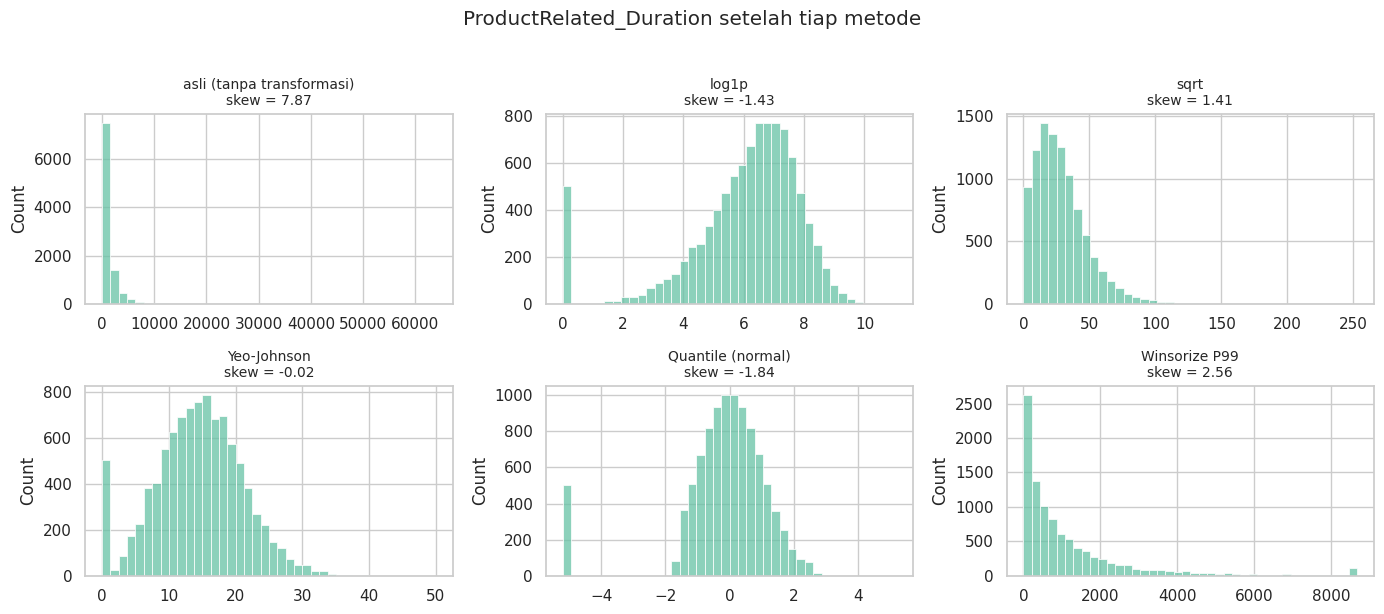

In [15]:
# (a) Bukti deskriptif: seberapa besar tiap metode menurunkan kemiringan? (dihitung pada DATA LATIH)
Xs = X_train[skew_cols]
variasi = {
    'asli (tanpa transformasi)': Xs,
    'log1p': np.log1p(Xs),
    'sqrt': np.sqrt(Xs),
    'Yeo-Johnson': pd.DataFrame(PowerTransformer(method='yeo-johnson', standardize=False).fit_transform(Xs), columns=skew_cols, index=Xs.index),
    'Quantile (normal)': pd.DataFrame(QuantileTransformer(output_distribution='normal', n_quantiles=200, random_state=RANDOM_STATE).fit_transform(Xs), columns=skew_cols, index=Xs.index),
    'Winsorize P99': Xs.clip(upper=Xs.quantile(0.99), axis=1),
}
skew_banding = pd.DataFrame({k: v.skew() for k, v in variasi.items()})
skew_banding.loc['RATA-RATA |skew|'] = skew_banding.abs().mean()
display(skew_banding.round(2))

# Bentuk sebaran satu fitur setelah tiap metode
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, (k, v) in zip(axes.ravel(), variasi.items()):
    sns.histplot(v['ProductRelated_Duration'], bins=40, ax=ax)
    ax.set_title(f"{k}\nskew = {v['ProductRelated_Duration'].skew():.2f}", fontsize=10); ax.set_xlabel("")
plt.suptitle("ProductRelated_Duration setelah tiap metode", y=1.02); plt.tight_layout(); plt.show()

**Interpretasi (a) penurunan kemiringan:** rata-rata |skew| turun dari 4,84 menjadi 0,68 (Yeo-Johnson), 0,91 (Quantile), 1,47 (`log1p`), 1,78 (`sqrt`), dan hanya 2,95 (Winsorize). Jadi **dari sisi memperbaiki bentuk sebaran, Yeo-Johnson paling efektif dan Winsorize paling lemah** (ekor hanya dipotong, bentuknya tetap miring). Pada fitur durasi, `log1p` jauh lebih kuat daripada `sqrt` (`Administrative_Duration`: 0,24 vs 1,54). Tidak ada metode yang menuntaskan `Informational` dan `Informational_Duration` (skew tersisa 1,4–3,5) karena 78–80% nilainya nol; tumpukan nol tidak bisa diratakan oleh transformasi apa pun.

=== DENGAN PageValues ===


,pr_auc_rata2,std_fold,selisih_vs_pilihan,std_selisih,menang_dari_15,putusan
metode,,,,,,
Tanpa transformasi,0.6474,0.0252,-0.0162,0.0116,1,lebih buruk
log1p (pilihan),0.6637,0.0215,0.0000,0.0000,0,(pilihan)
sqrt,0.6678,0.0225,0.0041,0.0080,11,setara
Yeo-Johnson,0.6410,0.0252,-0.0226,0.0137,1,lebih buruk
Quantile (normal),0.6487,0.0235,-0.0150,0.0107,1,lebih buruk
Winsorize P99,0.6493,0.0241,-0.0144,0.0085,1,lebih buruk


=== TANPA PageValues ===


,pr_auc_rata2,std_fold,selisih_vs_pilihan,std_selisih,menang_dari_15,putusan
metode,,,,,,
Tanpa transformasi,0.3221,0.0195,-0.0093,0.0097,2,setara
log1p (pilihan),0.3314,0.0247,0.0000,0.0000,0,(pilihan)
sqrt,0.3300,0.0221,-0.0014,0.0102,7,setara
Yeo-Johnson,0.3330,0.0231,0.0015,0.0076,8,setara
Quantile (normal),0.3354,0.0261,0.0040,0.0104,9,setara
Winsorize P99,0.3291,0.0212,-0.0023,0.0097,7,setara


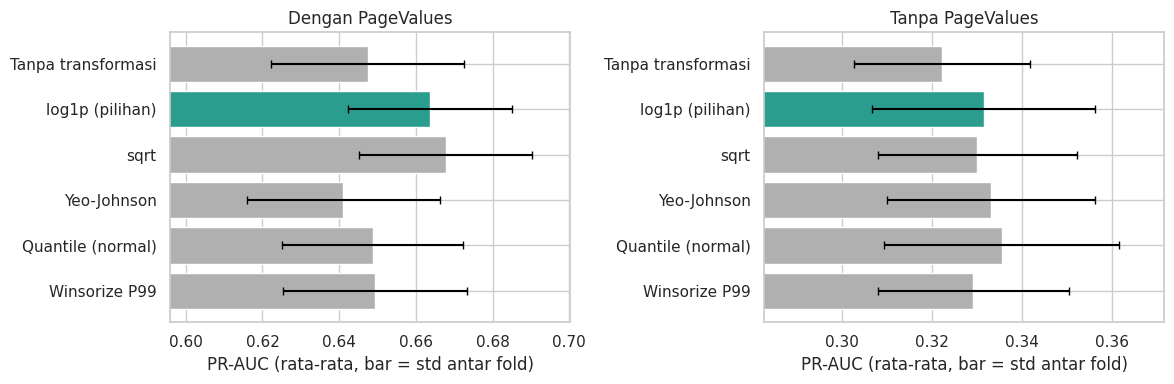

In [16]:
# (b) Bukti prediktif: PR-AUC Logistic Regression, CV 5x3 pada data latih. Dua skenario: dengan dan tanpa PageValues
nama_skew = {'none': 'Tanpa transformasi', 'log1p': 'log1p (pilihan)', 'sqrt': 'sqrt',
             'yeo': 'Yeo-Johnson', 'quantile': 'Quantile (normal)', 'clip': 'Winsorize P99'}
hasil_skew = {}
for pv in (False, True):
    hasil_skew[pv] = {nama_skew[k]: evaluasi(build_prep(skew=k, drop_pagevalues=pv)) for k in nama_skew}

tb_pv   = bandingkan(hasil_skew[False], 'log1p (pilihan)')
tb_nopv = bandingkan(hasil_skew[True],  'log1p (pilihan)')
print("=== DENGAN PageValues ===");  display(tb_pv.round(4))
print("=== TANPA PageValues ===");   display(tb_nopv.round(4))
gambar_cv([tb_pv, tb_nopv], ['Dengan PageValues', 'Tanpa PageValues'])

**Interpretasi (b) dampak ke prediksi:**

- **Dengan `PageValues`** (PR-AUC): `log1p` 0,6637 mengalahkan tanpa transformasi (0,6474; selisih −0,016, `log1p` menang di 14 dari 15 fold), Yeo-Johnson (0,6410), Quantile (0,6487), dan Winsorize (0,6493). Hanya `sqrt` (0,6678) yang setara: selisih +0,004 dengan simpangan baku 0,008, menang di 11 dari 15 fold, jadi **tidak terbukti lebih baik** dari `log1p`.
- **Tanpa `PageValues`**: semua metode setara (PR-AUC 0,322–0,335). Di skenario ini pilihan transformasi tidak mengubah hasil.

**Mengapa `log1p`:**
1. Terbukti lebih baik dari tanpa transformasi dan dari tiga metode lain saat `PageValues` dipakai.
2. Setara dengan `sqrt`, jadi `sqrt` juga bisa diterima. `log1p` dipertahankan karena menurunkan kemiringan lebih besar (1,47 vs 1,78), terutama pada fitur durasi.
3. Tidak punya parameter yang dipelajari dari data, jadi tidak ada risiko kebocoran dan mudah dijelaskan.
4. Winsorize ditolak dua kali: kurang efektif menurunkan skew, dan membuang informasi sesi ekstrem yang pada bagian 3 terbukti justru paling sering membeli.

**Catatan penting:** Yeo-Johnson paling efektif membuat sebaran mendekati normal, tetapi PR-AUC-nya paling rendah. Artinya **sebaran yang lebih normal tidak otomatis lebih prediktif**. Penyebabnya belum diuji; yang terlihat hanyalah bahwa `PageValues` (78% nol) sangat menentukan prediksi, jadi cara metode memperlakukan nol dan nilai kecil di fitur itu kemungkinan berpengaruh.

## 8.3 Scaling

Dibandingkan setelah `log1p`: `StandardScaler` (pilihan), `MinMaxScaler`, `RobustScaler` (median dan IQR), dan tanpa scaling.

,pr_auc_rata2,std_fold,selisih_vs_pilihan,std_selisih,menang_dari_15,putusan
metode,,,,,,
StandardScaler (pilihan),0.6637,0.0215,0.0000,0.0000,0,(pilihan)
MinMaxScaler,0.6633,0.0216,-0.0004,0.0005,3,setara
RobustScaler,0.6636,0.0214,-0.0000,0.0002,6,setara
Tanpa scaling,0.6615,0.0227,-0.0021,0.0017,1,lebih buruk


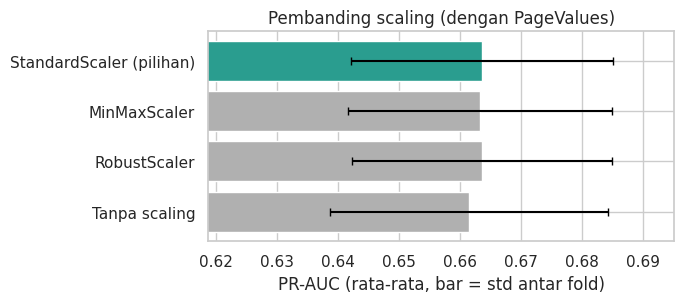

In [17]:
# Scaling (setelah log1p). Logistic Regression berregularisasi sensitif terhadap skala fitur.
nama_sc = {'standard': 'StandardScaler (pilihan)', 'minmax': 'MinMaxScaler', 'robust': 'RobustScaler', 'none': 'Tanpa scaling'}
hasil_sc = {nama_sc[k]: evaluasi(build_prep(scaler=k)) for k in nama_sc}
tb_sc = bandingkan(hasil_sc, 'StandardScaler (pilihan)')
display(tb_sc.round(4))
gambar_cv([tb_sc], ['Pembanding scaling (dengan PageValues)'], ukuran=(7, 3.2))

**Interpretasi:** `StandardScaler` (0,6637), `MinMaxScaler` (0,6633), dan `RobustScaler` (0,6636) **setara**. Tanpa scaling sedikit lebih rendah (0,6615; selisih −0,002, kalah di 14 dari 15 fold), kecil karena `log1p` sudah merapatkan rentang. Jadi scaling memang perlu untuk Logistic Regression, tetapi **memilih scaler yang mana tidak berpengaruh pada skor**. `StandardScaler` dipilih karena konvensional dan karena regularisasi L2 memperlakukan fitur adil bila semuanya berstandar deviasi sama. Ini alasan praktis, bukan hasil pembuktian bahwa ia terbaik.

## 8.4 Multikolinearitas

Dibandingkan: mempertahankan semua fitur, **melepas `BounceRates`** (pilihan), melepas `ExitRates`, melepas `BounceRates` bersama tiga kolom durasi, dan PCA (95% varians) pada blok numerik.

,pr_auc_rata2,std_fold,selisih_vs_pilihan,std_selisih,menang_dari_15,putusan
metode,,,,,,
Pertahankan semua fitur,0.6632,0.0220,-0.0005,0.0010,6,setara
Lepas BounceRates (pilihan),0.6637,0.0215,0.0000,0.0000,0,(pilihan)
Lepas ExitRates,0.6618,0.0227,-0.0019,0.0019,1,setara
Lepas BounceRates + 3 kolom durasi,0.6639,0.0212,0.0002,0.0012,9,setara


,pr_auc_rata2,std_fold,selisih_vs_pilihan,std_selisih,menang_dari_15,putusan
metode,,,,,,
Pertahankan semua fitur,0.6632,0.0220,-0.0005,0.0010,6,setara
Lepas BounceRates (pilihan),0.6637,0.0215,0.0000,0.0000,0,(pilihan)
Lepas ExitRates,0.6618,0.0227,-0.0019,0.0019,1,setara
Lepas BounceRates + 3 kolom durasi,0.6639,0.0212,0.0002,0.0012,9,setara
PCA (95% varians) pada numerik,0.6642,0.0214,0.0005,0.0017,9,setara


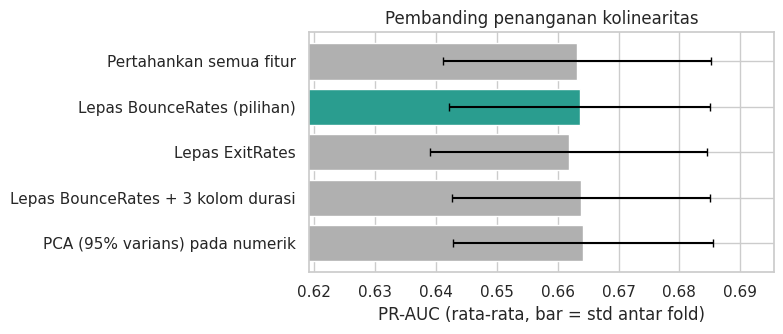

In [18]:
# Multikolinearitas: melepas fitur vs mempertahankan semuanya (regularisasi L2 bawaan LogisticRegression yang meredam)
durasi = ['Administrative_Duration', 'Informational_Duration', 'ProductRelated_Duration']
konf_col = {
    'Pertahankan semua fitur':                   (),
    'Lepas BounceRates (pilihan)':               ('BounceRates',),
    'Lepas ExitRates':                           ('ExitRates',),
    'Lepas BounceRates + 3 kolom durasi':        ('BounceRates',) + tuple(durasi),
}
hasil_col = {k: evaluasi(build_prep(drop=v)) for k, v in konf_col.items()}
tb_col = bandingkan(hasil_col, 'Lepas BounceRates (pilihan)')
display(tb_col.round(4))

# Pembanding tambahan: PCA pada blok numerik (menghilangkan kolinearitas sepenuhnya, tapi fitur tidak lagi bisa dibaca)
from sklearn.decomposition import PCA
prep_pca = build_prep(drop=())
prep_pca.set_params(num_skew=Pipeline(skew_step('log1p') + [('s', StandardScaler()), ('pca', PCA(n_components=0.95, random_state=RANDOM_STATE))]))
hasil_col['PCA (95% varians) pada numerik'] = evaluasi(prep_pca)
tb_col = bandingkan(hasil_col, 'Lepas BounceRates (pilihan)')
display(tb_col.round(4))
gambar_cv([tb_col], ['Pembanding penanganan kolinearitas'], ukuran=(8, 3.5))

**Interpretasi:** semua metode **setara** (PR-AUC 0,6618–0,6642). Mempertahankan seluruh fitur (0,6632) sama baiknya dengan melepas `BounceRates` (0,6637), sebab regularisasi L2 pada Logistic Regression sudah meredam kolinearitas. Jadi **melepas `BounceRates` tidak menaikkan skor; yang ia beri adalah koefisien yang lebih stabil dan mudah ditafsirkan** (VIF `ExitRates` turun dari 7,16 ke 2,50 pada bagian 5), tanpa biaya akurasi. Melepas `ExitRates` alih-alih `BounceRates` sedikit lebih rendah (−0,0019), searah dengan alasan EDA bahwa `ExitRates` lebih berkaitan dengan `Revenue`, tetapi selisihnya belum cukup besar untuk disebut berbeda. PCA juga setara, namun komponennya tidak bisa dibaca sebagai fitur asli, sehingga tidak dipilih. Bila tujuan hanya prediksi, mempertahankan semua fitur sama bagusnya.

## 8.5 Encoding dan kategori jarang

Notebook ini **sudah melakukan encoding**. Pilihan yang dibandingkan untuk kode `OperatingSystems`, `Browser`, `Region`, `TrafficType`: one-hot dengan penggabungan kode < 100 sesi (pilihan), one-hot tanpa penggabungan, ambang gabung 30 dan 300 sesi, serta ordinal encoding (kode dijadikan angka 0..k). Dua model dipakai karena model linear dan model pohon bereaksi berbeda terhadap encoding.

=== Logistic Regression ===


,pr_auc_rata2,std_fold,selisih_vs_pilihan,std_selisih,menang_dari_15,putusan
metode,,,,,,
"One-hot, gabung kode < 100 sesi (pilihan)",0.6637,0.0215,0.0000,0.0000,0,(pilihan)
"One-hot, tanpa penggabungan",0.6643,0.0215,0.0006,0.0013,10,setara
"One-hot, gabung < 30 sesi",0.6640,0.0217,0.0003,0.0011,10,setara
"One-hot, gabung < 300 sesi",0.6646,0.0224,0.0010,0.0025,9,setara
Ordinal (kode jadi angka 0..k),0.6638,0.0237,0.0002,0.0048,7,setara


=== Gradient Boosting ===


,pr_auc_rata2,std_fold,selisih_vs_pilihan,std_selisih,menang_dari_15,putusan
metode,,,,,,
"One-hot, gabung kode < 100 sesi (pilihan)",0.7289,0.0186,0.0000,0.0000,0,(pilihan)
"One-hot, tanpa penggabungan",0.7272,0.0199,-0.0017,0.0052,6,setara
"One-hot, gabung < 30 sesi",0.7294,0.0172,0.0005,0.0069,9,setara
"One-hot, gabung < 300 sesi",0.7266,0.0192,-0.0023,0.0078,5,setara
Ordinal (kode jadi angka 0..k),0.7252,0.0195,-0.0037,0.0094,4,setara


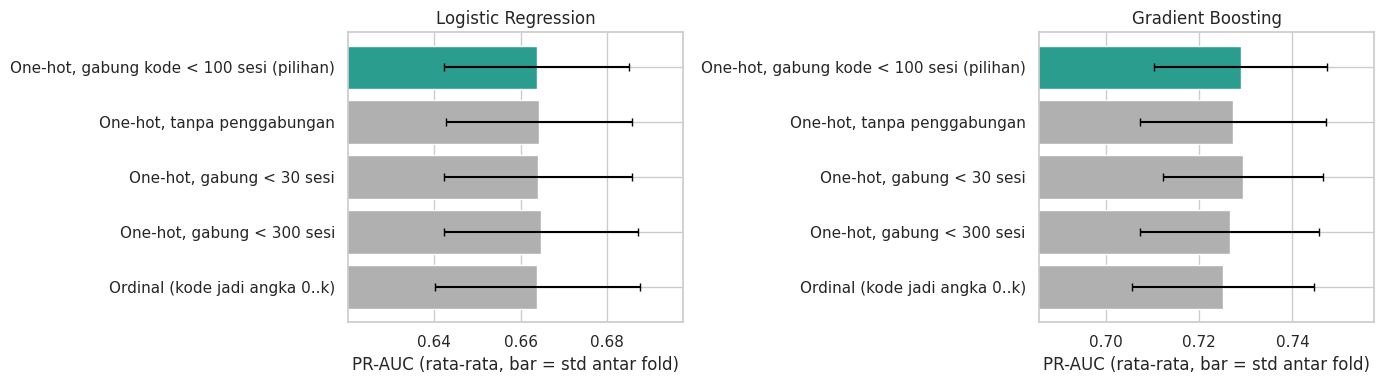

Jumlah kolom (jalur linear): {'One-hot, gabung kode < 100 sesi (pilihan)': 57, 'One-hot, tanpa penggabungan': 72, 'One-hot, gabung < 30 sesi': 64, 'One-hot, gabung < 300 sesi': 50, 'Ordinal (kode jadi angka 0..k)': 27}


In [19]:
# Encoding kode nominal (OS, Browser, Region, TrafficType): dibandingkan di DUA jenis model
konf_enc = {
    'One-hot, gabung kode < 100 sesi (pilihan)': dict(nominal_enc='onehot', min_freq=100),
    'One-hot, tanpa penggabungan':                dict(nominal_enc='onehot', min_freq=None),
    'One-hot, gabung < 30 sesi':                  dict(nominal_enc='onehot', min_freq=30),
    'One-hot, gabung < 300 sesi':                 dict(nominal_enc='onehot', min_freq=300),
    'Ordinal (kode jadi angka 0..k)':             dict(nominal_enc='ordinal'),
}
pilihan_enc = 'One-hot, gabung kode < 100 sesi (pilihan)'

# (1) Model linear
hasil_enc_lin = {k: evaluasi(build_prep('linear', **v)) for k, v in konf_enc.items()}
tb_enc_lin = bandingkan(hasil_enc_lin, pilihan_enc)
print("=== Logistic Regression ==="); display(tb_enc_lin.round(4))

# (2) Model pohon (Gradient Boosting)
hgb = lambda: HistGradientBoostingClassifier(class_weight='balanced', max_iter=150, random_state=RANDOM_STATE)
hasil_enc_tree = {k: evaluasi(build_prep('tree', skew='none', **v), clf=hgb()) for k, v in konf_enc.items()}
tb_enc_tree = bandingkan(hasil_enc_tree, pilihan_enc)
print("=== Gradient Boosting ==="); display(tb_enc_tree.round(4))
gambar_cv([tb_enc_lin, tb_enc_tree], ['Logistic Regression', 'Gradient Boosting'], ukuran=(14, 4))

# Jumlah kolom hasil tiap pilihan (biaya dimensi)
dim = {k: build_prep('linear', **v).fit(X_train).transform(X_train).shape[1] for k, v in konf_enc.items()}
print("Jumlah kolom (jalur linear):", dim)

**Interpretasi:** di kedua model semua pilihan **setara** (Logistic Regression 0,6637–0,6646; Gradient Boosting 0,7252–0,7294). Jadi data ini tidak membedakan cara encoding secara prediktif, dan ambang 100 sesi bukan ambang yang "terbukti paling baik" (30, 100, 300 setara). Alasan memilih one-hot dengan penggabungan:

- **Dimensi:** 57 kolom, dibanding 72 bila tanpa penggabungan, tanpa kehilangan skor. Kode yang hanya muncul puluhan kali menghasilkan koefisien yang tidak stabil.
- **Ordinal tidak cocok secara konsep** untuk model linear: kode seperti `Browser` 2 dan 3 adalah label, bukan urutan, sehingga ordinal memaksakan hubungan garis lurus yang tidak ada. Skornya di data ini kebetulan setara, tetapi simpangan baku selisihnya paling besar (0,0048 pada Logistic Regression), artinya paling tidak stabil antar fold. Pada Gradient Boosting ordinal juga memberi rata-rata terendah (0,7252). Ordinal hanya 27 kolom sehingga lebih ringkas, namun itu bukan alasan cukup.
- One-hot tetap dipakai di jalur pohon agar kedua jalur memakai aturan penggabungan yang sama.

## 8.6 Kelas tidak seimbang

Dibandingkan: `class_weight='balanced'` (pilihan), tanpa penanganan, *random over-sampling*, *random under-sampling*, dan SMOTE. Semua resampling dilakukan **di dalam fold** dan hanya pada data latih fold. Selain PR-AUC (tidak bergantung ambang), ditampilkan juga F1 pada ambang terbaik (`f1_maks`) dan recall/precision pada ambang bawaan 0,5, karena penanganan kelas terutama menggeser ambang.

In [20]:
# Penanganan kelas tidak seimbang. Semua resampling dilakukan DI DALAM fold (hanya pada data latih fold).
import subprocess, sys
try:
    import imblearn
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"])
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

lr = lambda cw: LogisticRegression(class_weight=cw, max_iter=3000, random_state=RANDOM_STATE)
hasil_imb = {
    'class_weight balanced (pilihan)': evaluasi(build_prep(), clf=lr('balanced')),
    'Tanpa penanganan':                evaluasi(build_prep(), clf=lr(None)),
    'RandomOverSampler':               evaluasi(build_prep(), clf=lr(None), sampler=RandomOverSampler(random_state=RANDOM_STATE)),
    'RandomUnderSampler':              evaluasi(build_prep(), clf=lr(None), sampler=RandomUnderSampler(random_state=RANDOM_STATE)),
    'SMOTE':                           evaluasi(build_prep(), clf=lr(None), sampler=SMOTE(random_state=RANDOM_STATE)),
}
tb_imb_pr = bandingkan(hasil_imb, 'class_weight balanced (pilihan)', 'pr_auc')
print("=== Logistic Regression: PR-AUC (tanpa ambang) ==="); display(tb_imb_pr.round(4))
tb_imb_f1 = bandingkan(hasil_imb, 'class_weight balanced (pilihan)', 'f1_maks')
print("=== Logistic Regression: F1 pada ambang terbaik ==="); display(tb_imb_f1.round(4))

# Metrik pada ambang 0,5 (inilah yang berubah oleh penanganan kelas)
kolom = ['pr_auc', 'roc_auc', 'recall', 'precision', 'f1', 'f1_maks']
ringkas = pd.DataFrame({k: {m: v[m].mean() for m in kolom} for k, v in hasil_imb.items()}).T
print("=== Rata-rata CV: ambang 0,5 (recall, precision, f1) vs ambang terbaik (f1_maks) ==="); display(ringkas.round(3))

# Hal yang sama untuk model pohon
hgb_cw = lambda cw: HistGradientBoostingClassifier(class_weight=cw, max_iter=150, random_state=RANDOM_STATE)
hasil_imb_tree = {
    'class_weight balanced (pilihan)': evaluasi(build_prep('tree', skew='none'), clf=hgb_cw('balanced')),
    'Tanpa penanganan':                evaluasi(build_prep('tree', skew='none'), clf=hgb_cw(None)),
}
ringkas_tree = pd.DataFrame({k: {m: v[m].mean() for m in kolom} for k, v in hasil_imb_tree.items()}).T
print("=== Gradient Boosting ==="); display(ringkas_tree.round(3))
print(bandingkan(hasil_imb_tree, 'class_weight balanced (pilihan)', 'pr_auc').round(4).to_string())

=== Logistic Regression: PR-AUC (tanpa ambang) ===


,pr_auc_rata2,std_fold,selisih_vs_pilihan,std_selisih,menang_dari_15,putusan
metode,,,,,,
class_weight balanced (pilihan),0.6637,0.0215,0.0000,0.0000,0,(pilihan)
Tanpa penanganan,0.6824,0.0196,0.0188,0.0052,15,lebih baik
RandomOverSampler,0.6633,0.0216,-0.0003,0.0016,6,setara
RandomUnderSampler,0.6622,0.0224,-0.0014,0.0041,4,setara
SMOTE,0.6609,0.0227,-0.0028,0.0024,1,lebih buruk


=== Logistic Regression: F1 pada ambang terbaik ===


,f1_maks_rata2,std_fold,selisih_vs_pilihan,std_selisih,menang_dari_15,putusan
metode,,,,,,
class_weight balanced (pilihan),0.6722,0.0162,0.0000,0.0000,0,(pilihan)
Tanpa penanganan,0.6736,0.0176,0.0014,0.0060,8,setara
RandomOverSampler,0.6705,0.0162,-0.0017,0.0027,5,setara
RandomUnderSampler,0.6696,0.0165,-0.0025,0.0048,5,setara
SMOTE,0.6682,0.0156,-0.0040,0.0060,4,setara


=== Rata-rata CV: ambang 0,5 (recall, precision, f1) vs ambang terbaik (f1_maks) ===


,pr_auc,roc_auc,recall,precision,f1,f1_maks
class_weight balanced (pilihan),0.664,0.916,0.796,0.544,0.645,0.672
Tanpa penanganan,0.682,0.912,0.548,0.702,0.615,0.674
RandomOverSampler,0.663,0.916,0.792,0.547,0.646,0.670
RandomUnderSampler,0.662,0.915,0.803,0.530,0.638,0.670
SMOTE,0.661,0.913,0.799,0.528,0.635,0.668


=== Gradient Boosting ===


,pr_auc,roc_auc,recall,precision,f1,f1_maks
class_weight balanced (pilihan),0.729,0.924,0.756,0.591,0.663,0.676
Tanpa penanganan,0.730,0.925,0.598,0.709,0.648,0.679


                                 pr_auc_rata2  std_fold  selisih_vs_pilihan  std_selisih  menang_dari_15    putusan
metode                                                                                                             
class_weight balanced (pilihan)        0.7289    0.0186              0.0000       0.0000               0  (pilihan)
Tanpa penanganan                       0.7302    0.0187              0.0013       0.0085               8     setara


**Interpretasi:**

- **Logistic Regression, PR-AUC:** tanpa penanganan (0,6824) justru **lebih tinggi** daripada bobot kelas (0,6637), selisih +0,019 dan menang di 15 dari 15 fold. Over-sampling (0,6633) dan under-sampling (0,6622) setara; SMOTE (0,6609) sedikit lebih rendah.
- **F1 pada ambang terbaik:** semuanya **setara** (0,668–0,674). Artinya bila ambang disetel, tidak ada metode yang menang.
- **Pada ambang 0,5:** bobot kelas menaikkan recall dari 0,55 menjadi 0,80 (precision turun dari 0,70 ke 0,54) pada Logistic Regression, dan dari 0,60 ke 0,76 pada Gradient Boosting. Efek bobot kelas pada dasarnya adalah **menggeser ambang keputusan**, bukan membuat model lebih pintar.
- **Gradient Boosting, PR-AUC:** bobot (0,7289) dan tanpa penanganan (0,7302) setara.

**Mengapa bobot kelas tetap dipilih:** sederhana, tidak menambah atau membuang baris, tidak membuat data sintetis, dan hasilnya setara dengan resampling (SMOTE, over- dan under-sampling tidak memberi tambahan apa pun). SMOTE juga kurang cocok di sini karena pada kolom one-hot ia menghasilkan nilai dummy pecahan.

**Yang perlu dicatat jujur:** untuk Logistic Regression, bobot kelas **tidak** terbukti terbaik untuk kualitas peringkat (PR-AUC). Di tahap modeling sebaiknya Logistic Regression dicoba **dengan dan tanpa bobot**, lalu ambangnya dipilih berdasarkan biaya intervensi.

## 8.7 Jalur pohon: apakah transformasi memang tidak perlu?

Dibandingkan di Gradient Boosting: fitur mentah (pilihan), `log1p`, Yeo-Johnson, dan Winsorize P99.

,pr_auc_rata2,std_fold,selisih_vs_pilihan,std_selisih,menang_dari_15,putusan
metode,,,,,,
Fitur mentah (pilihan),0.7289,0.0186,0.0000,0.0000,0,(pilihan)
log1p,0.7289,0.0186,0.0000,0.0000,1,setara
Yeo-Johnson,0.7289,0.0186,0.0000,0.0000,1,setara
Winsorize P99,0.7268,0.0176,-0.0021,0.0045,4,setara


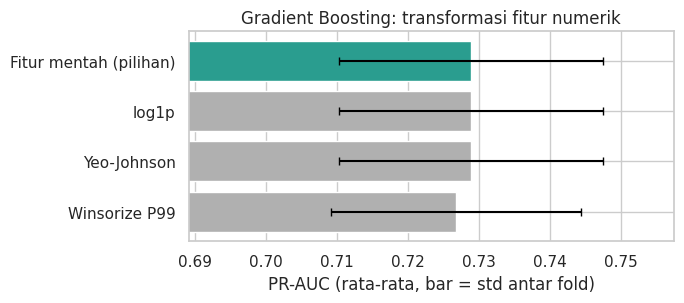

In [21]:
# Jalur pohon: apakah benar transformasi tidak berguna untuk model pohon?
konf_tree = {
    'Fitur mentah (pilihan)': 'none',
    'log1p':                  'log1p',
    'Yeo-Johnson':            'yeo',
    'Winsorize P99':          'clip',
}
hasil_tree = {k: evaluasi(build_prep('tree', skew=v), clf=hgb()) for k, v in konf_tree.items()}
tb_tree = bandingkan(hasil_tree, 'Fitur mentah (pilihan)')
display(tb_tree.round(4))
gambar_cv([tb_tree], ['Gradient Boosting: transformasi fitur numerik'], ukuran=(7, 3.2))

**Interpretasi:** fitur mentah, `log1p`, dan Yeo-Johnson memberi PR-AUC **identik** (0,7289) karena pohon hanya melihat urutan nilai dan kedua transformasi tersebut tidak mengubah urutan. Winsorize setara (0,7268; −0,002) dan tidak membantu karena memotong informasi di ekor. Ini mendukung keputusan **memakai fitur mentah untuk jalur pohon**: tidak ada manfaat dari transformasi, jadi tidak perlu menambah langkah.

## 8.8 Ringkasan bukti

| Keputusan | Pilihan | Pembanding (PR-AUC CV 5×3) | Putusan |
|---|---|---|---|
| Skewness (dengan `PageValues`) | `log1p` 0,6637 | Tanpa 0,6474; Yeo-Johnson 0,6410; Quantile 0,6487; Winsorize 0,6493; `sqrt` 0,6678 | `log1p` lebih baik dari 4 pembanding; setara `sqrt` |
| Skewness (tanpa `PageValues`) | `log1p` 0,3314 | Semua 0,322–0,335 | Semua setara |
| Menurunkan kemiringan (|skew| rata-rata) | `log1p` 1,47 | Yeo-Johnson 0,68; Quantile 0,91; `sqrt` 1,78; Winsorize 2,95 | Yeo-Johnson paling efektif, tetapi tidak lebih prediktif |
| Scaling | `StandardScaler` 0,6637 | MinMax 0,6633; Robust 0,6636; tanpa 0,6615 | Setara (tanpa scaling sedikit lebih rendah) |
| Kolinearitas | Lepas `BounceRates` 0,6637 | Semua fitur 0,6632; lepas `ExitRates` 0,6618; PCA 0,6642 | Setara; alasan pilihan: kestabilan koefisien |
| Encoding kode nominal | One-hot + gabung < 100 | Tanpa gabung, < 30, < 300, ordinal | Setara; one-hot + gabung lebih ringkas dan lebih tepat secara konsep |
| Kelas tidak seimbang | `class_weight` | Tanpa penanganan, over, under, SMOTE | F1 ambang terbaik setara; Logistic Regression tanpa bobot punya PR-AUC lebih tinggi (0,6824) |
| Jalur pohon | Fitur mentah 0,7289 | `log1p` 0,7289; Yeo-Johnson 0,7289; Winsorize 0,7268 | Setara; transformasi tidak perlu |

**Pelajaran dari perbandingan ini:**
1. Keputusan yang benar-benar berdampak hanya dua: **melakukan transformasi `log1p` pada jalur linear** dan **memasukkan atau tidak `PageValues`** (PR-AUC turun separuh tanpa fitur itu).
2. Sisanya (scaler, penanganan kolinearitas, cara encoding, resampling) memberi skor yang praktis sama. Pilihannya dibenarkan oleh kestabilan, keterbacaan, dan kesederhanaan, bukan oleh peningkatan akurasi.
3. Satu temuan yang perlu ditindaklanjuti: Logistic Regression tanpa bobot kelas memberi PR-AUC lebih tinggi.

# **9. PENANGANAN KELAS TIDAK SEIMBANG**

In [22]:
classes = np.array([0, 1])
w = compute_class_weight('balanced', classes=classes, y=y_train)
class_weight = dict(zip(classes, w))
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()   # untuk XGBoost/LightGBM bila dipakai

print("Bobot kelas ('balanced')    :", {k: round(v, 3) for k, v in class_weight.items()})
print(f"Rasio bukan-pembeli : pembeli: {scale_pos_weight:.2f} : 1")
print("Proporsi kelas test (tidak diubah):", y_test.value_counts(normalize=True).round(4).to_dict())

Bobot kelas ('balanced')    : {np.int64(0): np.float64(0.593), np.int64(1): np.float64(3.199)}
Rasio bukan-pembeli : pembeli: 5.40 : 1
Proporsi kelas test (tidak diubah): {0: 0.8435, 1: 0.1565}


**Interpretasi:** bobot kelas `balanced` memberi pembeli bobot 3,20 dan bukan-pembeli 0,59, artinya satu pembeli dihitung sekitar 5,4 kali bukan-pembeli (sesuai rasio kelas di data latih). Data uji sengaja **tidak diubah** (84,35% : 15,65%) agar evaluasi mencerminkan kondisi nyata. Resampling (over-sampling, under-sampling, SMOTE) sudah dibandingkan di bagian 8.6 **di dalam** pipeline cross-validation dan tidak lebih baik dari bobot kelas.

# **10. MENYIMPAN HASIL**

In [23]:
os.makedirs('data_processed', exist_ok=True)

# Data bersih + split (belum ditransformasi), supaya tahap modeling memakai pembagian yang sama persis
X_train.assign(Revenue=y_train).to_csv('data_processed/train.csv', index=False)
X_test.assign(Revenue=y_test).to_csv('data_processed/test.csv', index=False)

# Preprocessor yang sudah di-fit pada data latih (dengan dan tanpa PageValues)
joblib.dump({
    'linear': prep_linear,
    'tree': prep_tree,
    'linear_tanpa_pagevalues': make_preprocessor('linear', drop_pagevalues=True).fit(X_train),
    'tree_tanpa_pagevalues': make_preprocessor('tree', drop_pagevalues=True).fit(X_train),
    'class_weight': class_weight,
}, 'data_processed/preprocessors.joblib')

print(sorted(os.listdir('data_processed')))

['preprocessors.joblib', 'test.csv', 'train.csv']


In [24]:
# CSV hasil transformasi, hanya untuk dilihat/dipakai di luar notebook ini.
# Jangan dipakai ulang untuk CV atau tuning: scaling sudah dihitung dari seluruh data latih.
Xtr_lin.assign(Revenue=y_train).to_csv('data_processed/train_linear.csv', index=False)
Xte_lin.assign(Revenue=y_test).to_csv('data_processed/test_linear.csv', index=False)
Xtr_tree.assign(Revenue=y_train).to_csv('data_processed/train_tree.csv', index=False)
Xte_tree.assign(Revenue=y_test).to_csv('data_processed/test_tree.csv', index=False)

In [25]:
import zipfile

file_penting = ['train.csv', 'test.csv', 'preprocessors.joblib']
with zipfile.ZipFile('data_processed.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for f in file_penting:
        z.write(f'data_processed/{f}', arcname=f'data_processed/{f}')
print("Isi zip:", zipfile.ZipFile('data_processed.zip').namelist())

try:
    from google.colab import files
    files.download('data_processed.zip')
except ImportError:
    print("Bukan Google Colab, sel unduh dilewati. Zip ada di data_processed.zip.")

Isi zip: ['data_processed/train.csv', 'data_processed/test.csv', 'data_processed/preprocessors.joblib']
Bukan Google Colab, sel unduh dilewati. Zip ada di data_processed.zip.


# **11. KESIMPULAN PREPROCESSING**

## Ringkasan keputusan

| # | Keputusan | Alasan | Bukti |
|---|---|---|---|
| 1 | Revenue dan Weekend diubah menjadi 0/1 | Bisa langsung dipakai model | Tidak ada missing value |
| 2 | 125 duplikat dibuang sebelum split | Mencegah baris identik masuk train dan test | Semuanya `Revenue = False`; proporsi pembeli hanya bergeser 15,47% → 15,63% |
| 3 | Anomali kecil dipertahankan | Jumlahnya sedikit dan bukan label yang salah | Bagian 2.3 |
| 4 | Outlier tidak dibuang | Sesi ekstrem adalah perilaku nyata dan banyak berujung pembelian | Bagian 3 |
| 5 | `log1p` + standardisasi untuk jalur linear, fitur mentah untuk jalur pohon | Mengurangi kemiringan; pohon tidak membutuhkannya | Bagian 3, 8.2, 8.3, 8.7 |
| 6 | Stratified split 80:20 | Proporsi pembeli train dan test sama | Bagian 4 |
| 7 | `BounceRates` dilepas hanya di jalur linear | Mengurangi VIF `ExitRates` tanpa menurunkan PR-AUC | Bagian 5, 8.4 |
| 8 | Kode OS, Browser, Region, TrafficType di-one-hot; kode < 100 sesi digabung | Kode adalah label; kategori kecil mudah overfit | Bagian 6–7, 8.5 |
| 9 | Dua versi fitur: dengan dan tanpa `PageValues` | Menguji ketergantungan model pada fitur yang berisiko leakage | CV konfigurasi 3 vs 4 |
| 10 | Kelas tidak seimbang ditangani dengan bobot kelas, bukan resampling | Data uji tetap menggambarkan kondisi nyata | Bagian 8.6, 9 |

## Hasil perbandingan dengan metode lain (bagian 8.2–8.8)
- `log1p` mengalahkan tanpa transformasi, Yeo-Johnson, Quantile, dan Winsorize pada PR-AUC (dengan `PageValues`); setara dengan `sqrt`. Yeo-Johnson paling efektif menurunkan skew tetapi tidak lebih prediktif.
- Scaler, penanganan kolinearitas, dan cara encoding memberi skor setara. Pilihan dibenarkan oleh kestabilan dan kesederhanaan, bukan peningkatan skor.
- Bobot kelas setara dengan resampling pada F1 ambang terbaik, tetapi Logistic Regression tanpa bobot punya PR-AUC lebih tinggi; coba keduanya saat modeling.

## Catatan untuk tahap modeling
- Selalu pakai `make_preprocessor(...)` **di dalam** `Pipeline` saat cross-validation dan tuning agar scaling dan encoding dihitung ulang di tiap fold.
- Data uji dipakai **sekali** di akhir untuk evaluasi model terpilih.
- Evaluasi dengan PR-AUC, precision, recall, F1, dan confusion matrix. Threshold dipilih berdasarkan biaya intervensi, bukan 0,5 otomatis.
- Laporkan setiap model **dengan dan tanpa `PageValues`**.
- Uji Logistic Regression **dengan dan tanpa** `class_weight`, lalu pilih ambang keputusan.
- Karena tidak ada identitas pengguna, sesi dari pengguna yang sama masih bisa tersebar di train dan test. Skor uji kemungkinan sedikit optimistis.